In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("data/train.csv")
test  = pd.read_csv("data/test.csv")

print(train.shape, test.shape)   # (891, 12) (418, 11)
train.head()

(891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
train.isna().sum()



PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [4]:
test.isna().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [5]:
# Overall survival rate
train["Survived"].mean() 

0.3838383838383838

In [6]:
# Survival by sex
train.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [7]:
train.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [8]:
# Sex AND class together
train.pivot_table(index="Sex", columns="Pclass", values="Survived")

Pclass,1,2,3
Sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


In [9]:
#survival by port

In [10]:
train.groupby("Embarked")["Survived"].mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

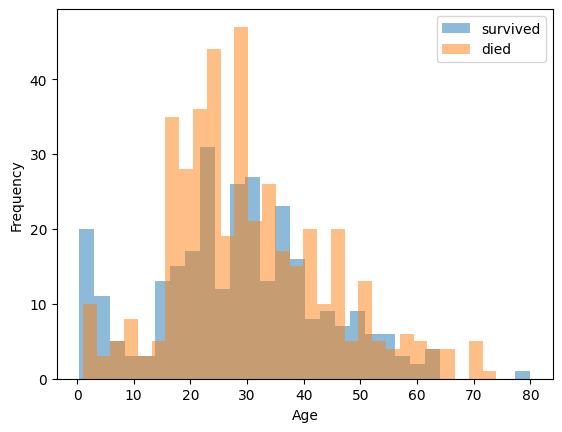

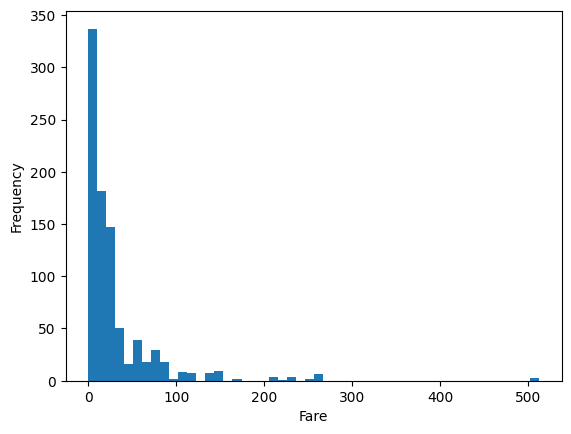

In [11]:
# Age distribution: survivors vs non-survivors
train[train.Survived == 1]["Age"].plot.hist(alpha=0.5, bins=30, label="survived")
train[train.Survived == 0]["Age"].plot.hist(alpha=0.5, bins=30, label="died")
plt.xlabel("Age"); plt.legend(); plt.show()

# Fare is very skewed (a few huge values)
train["Fare"].plot.hist(bins=50); plt.xlabel("Fare"); plt.show()

In [12]:
def extract_title(names):
    title = names.str.extract(r",\s*([^\.]+)\.")[0].str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    common = ["Mr", "Mrs", "Miss", "Master"]
    return title.where(title.isin(common), "Rare")

# Statistics learned from TRAIN only, then reused on test (avoids "data leakage")
train_titles = extract_title(train["Name"])
AGE_BY_TITLE = train.assign(Title=train_titles).groupby("Title")["Age"].median()
FARE_MEDIAN  = train["Fare"].median()

def prepare(df):
    out = pd.DataFrame(index=df.index)
    out["Sex"] = (df["Sex"] == "female").astype(int)

    title = extract_title(df["Name"])
    age = df["Age"].fillna(title.map(AGE_BY_TITLE))
    out["Age"] = age

    out["LogFare"]    = np.log1p(df["Fare"].fillna(FARE_MEDIAN))
    out["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    out["IsAlone"]    = (out["FamilySize"] == 1).astype(int)
    out["HasCabin"]   = df["Cabin"].notna().astype(int)

    embarked = df["Embarked"].fillna("S")
    # One-hot encode; fixed category lists so train and test get the same columns
    for c in [2, 3]:
        out[f"Pclass_{c}"] = (df["Pclass"] == c).astype(int)
    for t in ["Mrs", "Miss", "Master", "Rare"]:          # "Mr" is the default
        out[f"Title_{t}"] = (title == t).astype(int)
    for e in ["Q", "S"]:                                  # "C" is the default
        out[f"Embarked_{e}"] = (embarked == e).astype(int)
    return out

X_all  = prepare(train)
y_all  = train["Survived"].to_numpy()
X_kaggle = prepare(test)

print(X_all.shape)            
print(X_all.isna().sum().sum(), X_kaggle.isna().sum().sum())   
X_all.head()

(891, 14)
0 0


,Sex,Age,LogFare,FamilySize,IsAlone,HasCabin,Pclass_2,Pclass_3,Title_Mrs,Title_Miss,Title_Master,Title_Rare,Embarked_Q,Embarked_S
0,0,22.0,2.110213,2,0,0,0,1,0,0,0,0,0,1
1,1,38.0,4.280593,2,0,1,0,0,1,0,0,0,0,0
2,1,26.0,2.188856,1,1,0,0,1,0,1,0,0,0,1
3,1,35.0,3.990834,2,0,1,0,0,1,0,0,0,0,1
4,0,35.0,2.202765,1,1,0,0,1,0,0,0,0,0,1


In [13]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_all.to_numpy(dtype=float), y_all,
    test_size=0.2, random_state=42, stratify=y_all)

print(X_tr.shape, X_val.shape)    

(712, 14) (179, 14)


In [14]:
def zscore_fit(X):
    mu=X.mean(axis=0)
    sigma=X.std(axis=0)
    sigma[sigma == 0] = 1
    return mu,sigma

def zscore_apply(X, mu, sigma):
    
    return (X - mu) / sigma

mu, sigma = zscore_fit(X_tr)               
X_tr_s  = zscore_apply(X_tr,  mu, sigma)
X_val_s = zscore_apply(X_val, mu, sigma)  
X_kag_s = zscore_apply(X_kaggle.to_numpy(dtype=float), mu, sigma)

In [15]:
import numpy as np

def sigmoid(z):
    return 1/(1+np.exp(-z))


def compute_cost(X, y, w, b, lambda_=0.0):
    m = X.shape[0]
    f = sigmoid(X @ w + b)

    # Prevent log(0), which is undefined
    eps = 1e-15
    f = np.clip(f, eps, 1 - eps)

    log_loss = -np.sum(y * np.log(f) + (1 - y) * np.log(1 - f)) / m
    regularization = (lambda_ / (2 * m)) * np.sum(w ** 2)

    return log_loss + regularization      

def compute_gradient(X, y, w, b, lambda_=0.0):
    m = X.shape[0]
    f = sigmoid(X @ w + b)
    err = f - y

    dj_dw = (X.T @ err) / m + (lambda_ / m) * w
    dj_db = err.sum() / m

    return dj_dw, dj_db
   
def gradient_descent(X, y, w, b, alpha, num_iters, lambda_=0.0):
    J_history = []
    for _ in range(num_iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b, lambda_)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        J_history.append(compute_cost(X, y, w, b, lambda_))

    return w, b, J_history

def predict(X, w, b, threshold=0.5):
    probabilities = sigmoid(X @ w + b)
    return (probabilities >= threshold).astype(int)

In [16]:
n = X_tr_s.shape[1]
w0, b0 = np.zeros(n), 0.0

print(sigmoid(0))                              
print(sigmoid(np.array([-10, 0, 10])))         
print(compute_cost(X_tr_s, y_tr, w0, b0))      
dw, db = compute_gradient(X_tr_s, y_tr, w0, b0)
print(dw.shape, db)                            

0.5
[4.53978687e-05 5.00000000e-01 9.99954602e-01]
0.6931471805599453
(14,) 0.11657303370786516


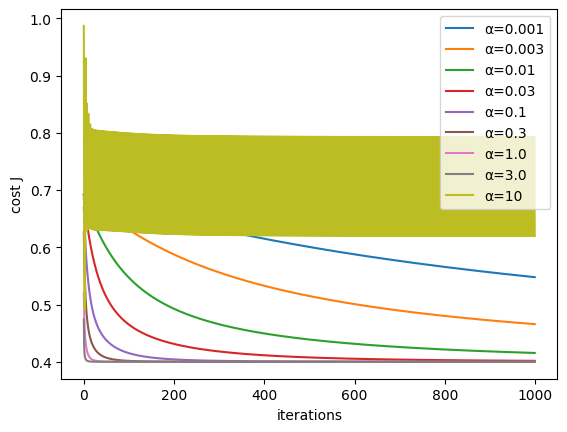

In [17]:
for alpha in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0,3.0,10]:
    w, b, J = gradient_descent(X_tr_s, y_tr, np.zeros(n), 0.0, alpha, 1000)
    plt.plot(J, label=f"α={alpha}")
plt.xlabel("iterations"); plt.ylabel("cost J"); plt.legend(); plt.show()

In [18]:
alpha = 0.1
w, b, J = gradient_descent(X_tr_s, y_tr, np.zeros(n), 0.0, alpha, 3000)
print("final cost:", J[-1])

final cost: 0.4002050049098161


In [19]:
def accuracy(y_true, y_pred):
    return (y_true == y_pred).mean()

print("train acc:", accuracy(y_tr,  predict(X_tr_s,  w, b)))
print("val acc:  ", accuracy(y_val, predict(X_val_s, w, b)))

train acc: 0.8286516853932584
val acc:   0.8435754189944135


In [20]:
for name, wj in sorted(zip(X_all.columns, w), key=lambda t: t[1]):
    print(f"{name:12s} {wj:+.3f}")

FamilySize   -0.817
Age          -0.442
Pclass_3     -0.427
Embarked_S   -0.143
IsAlone      -0.043
Pclass_2     -0.039
Embarked_Q   +0.077
Title_Rare   +0.125
Title_Miss   +0.308
LogFare      +0.448
HasCabin     +0.455
Title_Master +0.570
Title_Mrs    +0.592
Sex          +0.938


In [21]:
def add_extras(X_df):
    X = X_df.copy()
    X["Sex_x_Pclass3"] = X["Sex"] * X["Pclass_3"]      # women in 3rd class
    X["Age_sq"]        = X["Age"] ** 2
    X["Age_x_Sex"]     = X["Age"] * X["Sex"]
    X["Fare_x_Sex"]    = X["LogFare"] * X["Sex"]
    X["FamilySize_sq"] = X["FamilySize"] ** 2
    return X

In [22]:
# Add extra columns to both datasets
X_all_extra = add_extras(X_all)
X_kaggle_extra = add_extras(X_kaggle)

# Split the expanded training features and labels
X_tr, X_val, y_tr, y_val = train_test_split(
    X_all_extra.to_numpy(dtype=float),
    y_all,
    test_size=0.2,
    random_state=42,
    stratify=y_all
)

In [23]:
mu, sigma = zscore_fit(X_tr)

X_tr_s = zscore_apply(X_tr, mu, sigma)
X_val_s = zscore_apply(X_val, mu, sigma)
X_kag_s = zscore_apply(
    X_kaggle_extra.to_numpy(dtype=float),
    mu,
    sigma
)

In [24]:
n = X_tr_s.shape[1]
w, b, J = gradient_descent(
    X_tr_s, y_tr, np.zeros(n), 0.0,
    alpha=0.1, num_iters=3000
)

In [25]:
print(X_tr.shape, X_val.shape, X_kag_s.shape)

(712, 19) (179, 19) (418, 19)


In [26]:
print(accuracy(y_val, predict(X_val_s, w, b)))

0.8324022346368715


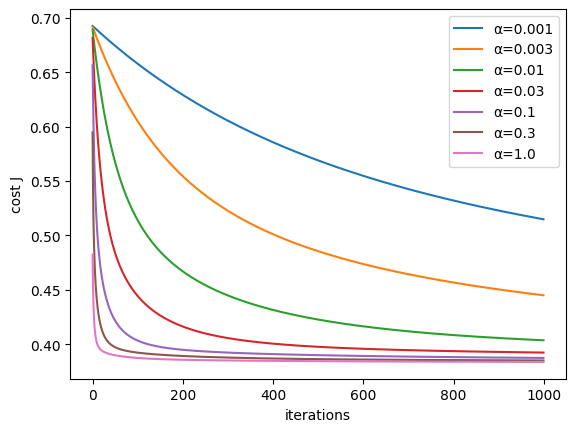

In [27]:
for alpha in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]:
    w, b, J = gradient_descent(X_tr_s, y_tr, np.zeros(n), 0.0, alpha, 1000)
    plt.plot(J, label=f"α={alpha}")
plt.xlabel("iterations"); plt.ylabel("cost J"); plt.legend(); plt.show()

In [28]:
alpha = 0.1
w, b, J = gradient_descent(X_tr_s, y_tr, np.zeros(n), 0.0, alpha, 3000)
print("final cost:", J[-1])

final cost: 0.38497016000125445


In [29]:
def accuracy(y_true, y_pred):
    return (y_true == y_pred).mean()

print("train acc:", accuracy(y_tr,  predict(X_tr_s,  w, b)))
print("val acc:  ", accuracy(y_val, predict(X_val_s, w, b)))

train acc: 0.848314606741573
val acc:   0.8324022346368715


In [30]:
for name, wj in sorted(zip(X_all.columns, w), key=lambda t: t[1]):
    print(f"{name:12s} {wj:+.3f}")

Age          -0.546
FamilySize   -0.317
Pclass_2     -0.175
Embarked_S   -0.157
Pclass_3     -0.151
IsAlone      +0.078
Embarked_Q   +0.099
Title_Rare   +0.157
LogFare      +0.370
HasCabin     +0.478
Title_Master +0.559
Title_Miss   +0.586
Title_Mrs    +0.797
Sex          +1.182


In [31]:
for lambda_ in [0, 0.01, 0.1, 1, 3, 10, 30, 100]:
    w, b, _ = gradient_descent(X_tr_s, y_tr, np.zeros(X_tr_s.shape[1]), 0.0,
                               alpha, 3000, lambda_)
    print(f"λ={lambda_:<6} train={accuracy(y_tr, predict(X_tr_s, w, b)):.3f} "
          f"val={accuracy(y_val, predict(X_val_s, w, b)):.3f}")

λ=0      train=0.848 val=0.832
λ=0.01   train=0.848 val=0.832
λ=0.1    train=0.848 val=0.832
λ=1      train=0.847 val=0.832
λ=3      train=0.846 val=0.832
λ=10     train=0.847 val=0.832
λ=30     train=0.840 val=0.821
λ=100    train=0.827 val=0.821


In [32]:
for th in [0.3, 0.4, 0.5, 0.6, 0.7]:
    print(th, accuracy(y_val, predict(X_val_s, w, b, threshold=th)))

0.3 0.770949720670391
0.4 0.8044692737430168
0.5 0.8212290502793296
0.6 0.7932960893854749
0.7 0.7430167597765364


In [33]:
from sklearn.linear_model import LogisticRegression

lambda_ = 0.1
clf = LogisticRegression(C=1/lambda_, max_iter=5000)
clf.fit(X_tr_s, y_tr)

print("sklearn val acc:", clf.score(X_val_s, y_val))
print("sklearn w:", np.round(clf.coef_[0], 3))
print("yours   w:", np.round(w, 3))

sklearn val acc: 0.8324022346368715
sklearn w: [ 2.39  -0.503  0.423  0.295  0.218  0.468 -0.207 -0.118  0.671  0.385
  0.54   0.156  0.087 -0.16  -1.008  0.162 -0.469 -0.398 -1.131]
yours   w: [ 0.315 -0.149  0.19  -0.116 -0.051  0.267  0.025 -0.212  0.192  0.196
  0.2    0.047  0.042 -0.13  -0.078 -0.083  0.231  0.297 -0.16 ]


In [34]:
preds = predict(X_kag_s, w, b)
submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": preds.astype(int)})
submission.to_csv("submission.csv", index=False)
submission.head()         

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [35]:
import numpy as np

columns = X_all_extra.columns.to_numpy()

np.savez(
    "model.npz",
    w=w,
    b=b,
    mu=mu,
    sigma=sigma,
    columns=columns
)

In [36]:
np.savez(
    "model.npz",
    w=w,
    b=b,
    mu=mu,
    sigma=sigma,
    columns=X_all_extra.columns.to_numpy(),
    age_by_title=AGE_BY_TITLE.to_dict(),
    fare_median=FARE_MEDIAN
)

In [37]:
w, b, _ = gradient_descent(
    X_tr_s, y_tr, np.zeros(X_tr_s.shape[1]), 0.0,
    alpha, 3000, 0.1
)

for th in [0.3, 0.4, 0.5, 0.6, 0.7]:
    print(th, accuracy(y_val, predict(X_val_s, w, b, threshold=th)))

0.3 0.7988826815642458
0.4 0.8324022346368715
0.5 0.8324022346368715
0.6 0.8491620111731844
0.7 0.7877094972067039


In [38]:
w, b, _ = gradient_descent(
    X_tr_s, y_tr, np.zeros(X_tr_s.shape[1]), 0.0,
    alpha, 3000, 0.1
)


print(th, accuracy(y_val, predict(X_val_s, w, b, threshold=0.6)))

0.7 0.8491620111731844


In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

sklearn_model = LogisticRegression(C=1.0, max_iter=1000)
sklearn_model.fit(X_tr_s, y_tr)

print("sklearn train acc:", accuracy_score(y_tr, sklearn_model.predict(X_tr_s)))
print("sklearn val acc:  ", accuracy_score(y_val, sklearn_model.predict(X_val_s)))

sklearn train acc: 0.8455056179775281
sklearn val acc:   0.8268156424581006
